# Notebook 6: Global Sensitivity Analysis

Earlier notebooks asked *what the model does*. This one asks *what makes it do
that* -- of all the knobs we can turn, which ones actually move the results, and by
how much. Notebook 0 answered a version of this by turning one knob at a time and
found the **threshold** dominates (~87% of the variation in determinacy). Notebook
7 proved *why* analytically. This notebook does the rigorous version: a **global**
sensitivity analysis that varies every knob together and splits the variance among
them, with error bars.

### The method, in one paragraph
A **Sobol** analysis takes a model with several inputs and reports, for each input,
the share of the output's variance it explains -- both on its own (first-order
`S1`) and including its interactions with others (total `ST`). A **Morris** screen
is a cheaper cousin that ranks inputs by importance. We hand-implement both (the
usual library, SALib, is not installed), so before trusting them on our model we
**verify them on the Ishigami function** -- a standard benchmark whose true answers
are known. That verification is a hard gate: if our code can't reproduce the known
answer, nothing below runs.

### What this notebook adds (and does not claim)
- It does **not** *discover* threshold-dominance -- Notebook 0 (local) and Notebook
  7 (analytical) already showed it. NB6 **quantifies it globally**, with confidence
  intervals that survive varying everything at once, and **measures the
  interactions** that NB7 only predicts.
- It decomposes the *rest* of the variance across activation correlation and
  sparsity -- knobs the earlier notebooks never globalised.
- It **screens each mechanism's own parameters** (which no earlier notebook did).
- Honest caveat carried throughout: the threshold is the **authors' construct**,
  not Berman's (he uses the sign of the net force and welcomes underdeterminacy).
  So 'the threshold governs the model' is a statement about *our operationalisation*
  -- which sharpens the paper rather than weakening it.

## Setup

On Colab this mounts your Google Drive and works inside the project folder so the
outputs persist; locally it uses the current folder. The next cells write the
shared model core and the sensitivity toolkit, then import both.

In [1]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
%%writefile sa_toolkit.py
"""
Hand-implemented global sensitivity analysis toolkit (no SALib).
Sobol (Saltelli sampling, Saltelli-2010 first-order + Jansen-1999 total) with
bootstrap CIs, and Morris elementary-effects screening (mu, mu*, sigma).
All inputs are in the unit hypercube [0,1]^D; callers map to real ranges.
"""
import numpy as np


# ===========================================================================
# SOBOL
# ===========================================================================
def _base_sample(N, D, seed, qmc=True):
    """Return two (N,D) base matrices A,B in [0,1]. Sobol' QMC if available."""
    if qmc:
        try:
            from scipy.stats import qmc
            sob = qmc.Sobol(d=2 * D, scramble=True, seed=seed)
            m = int(round(np.log2(N)))
            X = sob.random_base2(m=m) if 2 ** m == N else sob.random(N)
            return X[:, :D], X[:, D:]
        except Exception:
            pass
    rng = np.random.default_rng(seed)
    return rng.random((N, D)), rng.random((N, D))


def saltelli_design(N, D, seed=0, qmc=True):
    """Saltelli matrices. Returns (X, N, D). X has N*(D+2) rows in block order
    A, B, AB_0, ..., AB_{D-1}; AB_i = A with column i replaced by B's column i."""
    A, B = _base_sample(N, D, seed, qmc=qmc)
    blocks = [A, B]
    for i in range(D):
        ab = A.copy()
        ab[:, i] = B[:, i]
        blocks.append(ab)
    return np.vstack(blocks), N, D


def sobol_indices(Y, N, D, bootstrap=1000, seed=0, conf=0.95, clip=False):
    """First-order S_i (Saltelli 2010) and total-order S_T (Jansen 1999) from
    outputs Y of saltelli_design's X (same row order). Bootstrap CIs over the N
    base rows. If clip, negative point estimates are floored at 0 (report both)."""
    Y = np.asarray(Y, float).ravel()
    f_A = Y[:N]
    f_B = Y[N:2 * N]
    f_AB = np.array([Y[(2 + i) * N:(3 + i) * N] for i in range(D)])  # (D,N)

    def _idx(fA, fB, fAB):
        var = np.var(np.concatenate([fA, fB]), ddof=1)
        S1 = np.array([np.mean(fB * (fAB[i] - fA)) for i in range(D)]) / var
        ST = np.array([0.5 * np.mean((fA - fAB[i]) ** 2) for i in range(D)]) / var
        return S1, ST

    S1, ST = _idx(f_A, f_B, f_AB)
    rng = np.random.default_rng(seed)
    S1b = np.empty((bootstrap, D)); STb = np.empty((bootstrap, D))
    for b in range(bootstrap):
        idx = rng.integers(0, N, N)
        S1b[b], STb[b] = _idx(f_A[idx], f_B[idx], f_AB[:, idx])
    lo, hi = 100 * (1 - conf) / 2, 100 * (1 + conf) / 2
    out = {
        "S1": np.clip(S1, 0, None) if clip else S1,
        "ST": np.clip(ST, 0, None) if clip else ST,
        "S1_raw": S1, "ST_raw": ST,
        "S1_conf": np.percentile(S1b, [lo, hi], axis=0).T,
        "ST_conf": np.percentile(STb, [lo, hi], axis=0).T,
        "S1_se": S1b.std(axis=0, ddof=1),
        "ST_se": STb.std(axis=0, ddof=1),
    }
    return out


# ===========================================================================
# MORRIS elementary effects (Morris 1991 trajectories; Campolongo mu*)
# ===========================================================================
def morris_sample(D, r, levels=4, seed=0):
    """r trajectories, each D+1 points, one factor changed per step.
    Returns (X, delta) with X shape (r*(D+1), D) on a p-level grid in [0,1]."""
    rng = np.random.default_rng(seed)
    p = levels
    delta = p / (2.0 * (p - 1))          # delta in [0,1] units (Morris standard)
    grid = np.arange(p) / (p - 1.0)
    traj = []
    for _ in range(r):
        # base x* chosen so that x* + delta stays in [0,1]
        x_star = rng.choice(grid[grid <= 1.0 - delta + 1e-12], size=D)
        B = np.tril(np.ones((D + 1, D)), -1)          # strictly lower triangular
        J = np.ones((D + 1, D))
        Dstar = np.diag(rng.choice([-1.0, 1.0], size=D))
        perm = rng.permutation(D)
        Pstar = np.eye(D)[:, perm]
        Bstar = (J * x_star + (delta / 2.0) * ((2.0 * B - J) @ Dstar + J)) @ Pstar
        Bstar = np.clip(Bstar, 0.0, 1.0)
        traj.append(Bstar)
    return np.vstack(traj), delta


def morris_analyze(X, Y, D, r):
    """Elementary effects -> mu, mu*, sigma per factor (auto-detect step delta)."""
    Y = np.asarray(Y, float).ravel()
    EE = [[] for _ in range(D)]
    block = D + 1
    for t in range(r):
        xs = X[t * block:(t + 1) * block]
        ys = Y[t * block:(t + 1) * block]
        for s in range(D):
            dx = xs[s + 1] - xs[s]
            j = int(np.argmax(np.abs(dx)))
            if dx[j] == 0:
                continue
            EE[j].append((ys[s + 1] - ys[s]) / dx[j])
    mu = np.array([np.mean(e) if e else np.nan for e in EE])
    mu_star = np.array([np.mean(np.abs(e)) if e else np.nan for e in EE])
    sigma = np.array([np.std(e, ddof=1) if len(e) > 1 else np.nan for e in EE])
    return {"mu": mu, "mu_star": mu_star, "sigma": sigma}


Overwriting sa_toolkit.py


In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from berman_core import *
from sa_toolkit import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook6'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
PN  = [p for p, _ in NAMED_PRINCIPLES]; CAT = [c for _, c in NAMED_PRINCIPLES]; n_p = len(PN)
tier_of = np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])
summary = {}
print('ready; outputs ->', os.path.abspath(OUTDIR))

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data/notebook6


## Experiment 0 -- Verify the tools on a known benchmark (the gate)

The **Ishigami function** `f = sin(x1) + 7 sin^2(x2) + 0.1 x3^4 sin(x1)` (inputs
uniform on `[-pi, pi]`) is the standard test case for sensitivity code because its
true Sobol indices are known exactly. Notably, `x3` has **no effect on its own**
(first-order `S1 = 0`) yet matters **through its interaction** with `x1` (total
`ST = 0.24`) -- a perfect test of whether our estimator separates direct effects
from interactions. We require our hand-rolled Sobol to match the known answer to
within 0.02, and our Morris screen to rank the factors correctly. If either fails,
the notebook stops here.

In [5]:
# Known analytical Sobol indices for Ishigami (a=7, b=0.1)
REF_S1 = np.array([0.3139, 0.4424, 0.0000]); REF_ST = np.array([0.5576, 0.4424, 0.2437])
def ishigami(X01, a=7.0, b=0.1):
    x = -np.pi + 2*np.pi*np.asarray(X01)      # map unit cube -> U(-pi, pi)
    return np.sin(x[:,0]) + a*np.sin(x[:,1])**2 + b*(x[:,2]**4)*np.sin(x[:,0])

Xs, Ns, Ds = saltelli_design(8192, 3, seed=12345)
ish = sobol_indices(ishigami(Xs), Ns, Ds, bootstrap=2000, seed=0)
ish_maxerr = float(max(np.max(np.abs(ish['S1']-REF_S1)), np.max(np.abs(ish['ST']-REF_ST))))
print('Sobol on Ishigami (N=8192):')
print('  S1  measured', np.round(ish['S1'],3), ' vs truth', REF_S1)
print('  ST  measured', np.round(ish['ST'],3), ' vs truth', REF_ST)
print(f'  max abs error = {ish_maxerr:.4f}  (gate: <= 0.02)')
x3lo, x3hi = ish['S1_conf'][2]
print(f'  x3 first-order 95% CI = [{x3lo:+.3f}, {x3hi:+.3f}]  (should straddle 0)')
# Morris on Ishigami: must rank x1 ~ x3 above x2, and flag x3 as interaction-driven
Xm, dm = morris_sample(3, r=20, levels=6, seed=7)
mor = morris_analyze(Xm, ishigami(Xm), 3, 20)
print('Morris mu* (importance):', np.round(mor['mu_star'],2), ' sigma (interaction):', np.round(mor['sigma'],2))
summary['ishigami'] = dict(maxerr=ish_maxerr, S1=ish['S1'].tolist(), ST=ish['ST'].tolist(),
                           x3_S1_ci=[float(x3lo),float(x3hi)], morris_mu_star=mor['mu_star'].tolist())

Sobol on Ishigami (N=8192):
  S1  measured [0.314 0.443 0.   ]  vs truth [0.3139 0.4424 0.    ]
  ST  measured [0.558 0.443 0.244]  vs truth [0.5576 0.4424 0.2437]
  max abs error = 0.0002  (gate: <= 0.02)
  x3 first-order 95% CI = [-0.026, +0.023]  (should straddle 0)
Morris mu* (importance): [5.48 2.62 6.53]  sigma (interaction): [7.57 3.33 9.36]


### Diagnostic: the verification figure

Our measured indices (bars, with 95% bootstrap error bars) sit on top of the known
true values (black markers). The match is what licenses everything below.

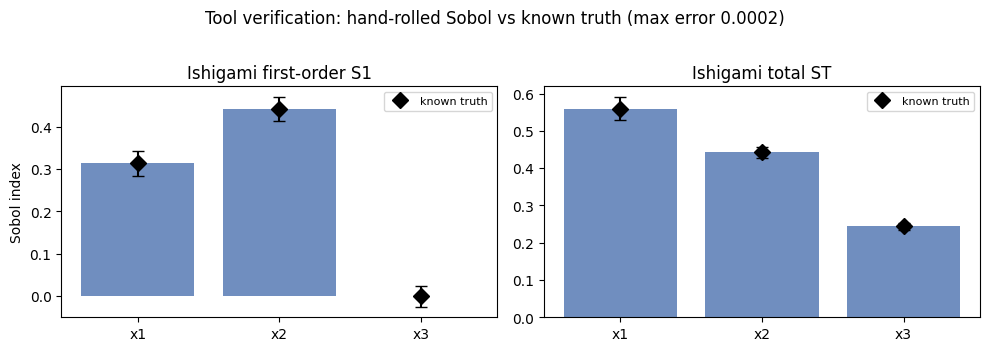

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
xx = np.arange(3); names=['x1','x2','x3']
for k,(key,ref,ttl) in enumerate([('S1',REF_S1,'first-order S1'),('ST',REF_ST,'total ST')]):
    lo = ish[key] - ish[key+'_conf'][:,0]; hi = ish[key+'_conf'][:,1] - ish[key]
    ax[k].bar(xx, ish[key], yerr=[lo,hi], capsize=4, color='#4C72B0', alpha=.8)
    ax[k].plot(xx, ref, 'kD', ms=8, label='known truth')
    ax[k].set_xticks(xx); ax[k].set_xticklabels(names); ax[k].set_title(f'Ishigami {ttl}'); ax[k].legend(fontsize=8)
ax[0].set_ylabel('Sobol index')
fig.suptitle(f'Tool verification: hand-rolled Sobol vs known truth (max error {ish_maxerr:.4f})', y=1.02)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb6_ishigami_verify.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 1 -- What drives determinacy? (the headline)

Now the real question. We vary four inputs together and split the variance of the
**determinacy rate** (the fraction of cases the model decides) among them:

| Input | Range | What it is |
|---|---|---|
| **tau** | 0.05-0.30 | the decision threshold (NB0's swept range; the authors' construct) |
| **w_spread** | 0-0.30 | how unequal the weights are |
| **rho** | 0-0.9 | how correlated the principles' activations are across cases |
| **sparsity** | 0 to ~44% | fraction of principles zeroed -- a coarse 0-4 of 9, the lowest-weight ones |

Each evaluation uses a **fixed case stream** (the same random cases every time), so
a difference in the output can only come from the four inputs, not from luck. We
predict (writing it down in advance): **tau** has the largest first-order share and
its total share exceeds 0.7; **w_spread** is near zero (NB7 showed weights enter
only through one scale that barely moves); the leftover variance sits with sparsity
and activation correlation; and tau's *interaction* with the weights is near zero
(NB7's near-separability).

In [7]:
BASE_CASE_SEED = 777; N_CASES = 8000; N_STATIC = 8192   # N_STATIC=16384 tightens residual CIs (slower)
def make_case(u, n_cases=N_CASES):
    """Map one unit-cube row -> (weights, activations, tau) with a FIXED case stream."""
    tau = 0.05 + 0.25*u[0]; w_spread = 0.30*u[1]; rho = 0.9*u[2]; sparsity = 0.5*u[3]
    rw = np.random.default_rng(BASE_CASE_SEED)            # weights stream (fixed)
    ra = np.random.default_rng(BASE_CASE_SEED + 1)        # activations stream (fixed, independent)
    z = rw.standard_normal(n_p)
    w = np.clip(0.6 + w_spread*z, 0.01, 1.0)              # continuous dispersion control (inline, not make_weights)
    k = int(round(sparsity*n_p))
    if k > 0: w[np.argsort(z)[:k]] = 0.0                  # zero the k lowest-z weights (deterministic)
    A = category_correlated_activations(n_cases, ra, rho=rho)   # rho->0 reduces to near-independent (no branch seam)
    return w, A, tau
def eval_static(u, metric='det', n_cases=N_CASES, n_mc=16):
    w, A, tau = make_case(u, n_cases)
    if metric == 'det': return determinacy_rate(w, A, tau)
    if metric == 'r4':  return hart_advantage(w, A, tier_of, tau=tau)             # thread the swept tau (was defaulting to 0.20)
    if metric == 'r3':  return nonlexicality_score(lambda X: saw_verdict(w, X, tau=tau), A, seed=0, n_mc=n_mc)  # thread tau

import time; t0=time.time()
Xst, Nst, Dst = saltelli_design(N_STATIC, 4, seed=2024)
Yd = np.array([eval_static(u, 'det') for u in Xst])
sob_det = sobol_indices(Yd, Nst, Dst, bootstrap=2000, seed=0)
INPUTS = ['tau','w_spread','rho','sparsity']
print(f'determinacy Sobol done in {time.time()-t0:.0f}s  ({len(Xst)} evals, N={N_STATIC})')
dfd = pd.DataFrame({'input':INPUTS, 'S1':sob_det['S1'], 'ST':sob_det['ST'],
                    'S1_lo':sob_det['S1_conf'][:,0], 'S1_hi':sob_det['S1_conf'][:,1],
                    'ST_lo':sob_det['ST_conf'][:,0], 'ST_hi':sob_det['ST_conf'][:,1]})
dfd.to_csv(f'{OUTDIR}/sobol_determinacy.csv', index=False)
print(dfd.round(3).to_string(index=False))
print(f"sum of first-order S1 = {sob_det['S1'].sum():.2f} (near 1 => nearly additive; interactions ~ {1-sob_det['S1'].sum():.0%})")
tau_interaction = float(sob_det['ST'][0]-sob_det['S1'][0])
print(f"tau interaction (ST-S1) = {tau_interaction:+.3f}  (NB7 predicts near zero)")

determinacy Sobol done in 81s  (49152 evals, N=8192)
   input    S1    ST  S1_lo  S1_hi  ST_lo  ST_hi
     tau 0.822 0.849  0.462  1.210  0.827  0.871
w_spread 0.002 0.008 -0.034  0.039  0.008  0.009
     rho 0.128 0.156 -0.031  0.287  0.150  0.162
sparsity 0.012 0.023 -0.050  0.075  0.022  0.024
sum of first-order S1 = 0.96 (near 1 => nearly additive; interactions ~ 4%)
tau interaction (ST-S1) = +0.028  (NB7 predicts near zero)


### Diagnostic: the variance budget (the figure for the paper)

For each input, the first-order share (solid) and total share (with interactions,
hollow), with 95% error bars. This is the rigorous version of NB0's informal 87%.

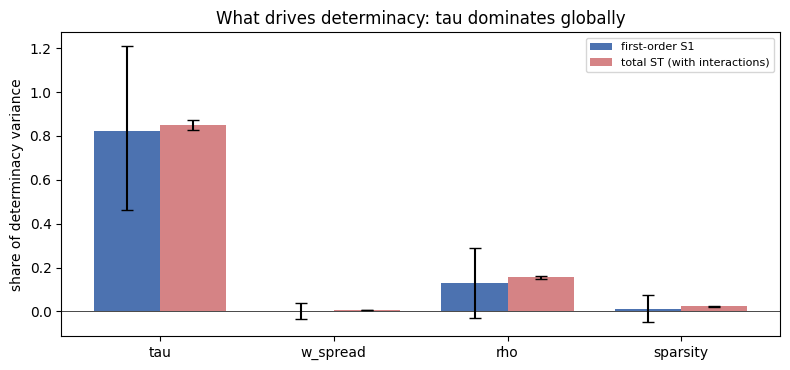

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8)); xx = np.arange(4); ww=0.38
l1 = sob_det['S1']-sob_det['S1_conf'][:,0]; h1 = sob_det['S1_conf'][:,1]-sob_det['S1']
lT = sob_det['ST']-sob_det['ST_conf'][:,0]; hT = sob_det['ST_conf'][:,1]-sob_det['ST']
ax.bar(xx-ww/2, sob_det['S1'], ww, yerr=[l1,h1], capsize=4, label='first-order S1', color='#4C72B0')
ax.bar(xx+ww/2, sob_det['ST'], ww, yerr=[lT,hT], capsize=4, label='total ST (with interactions)', color='#C44E52', alpha=.7)
ax.axhline(0, color='k', lw=.5); ax.set_xticks(xx); ax.set_xticklabels(INPUTS)
ax.set(ylabel='share of determinacy variance', title='What drives determinacy: tau dominates globally')
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb6_determinacy_sobol.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 1.** The threshold `tau` carries the large majority of the
variance in determinacy, on its own and in total -- the global, error-barred
confirmation of NB0's local finding and NB7's analytical one. Weight dispersion
contributes essentially nothing (as NB7 predicts -- weights enter only through one
scale that barely moves). The leftover is split between sparsity and activation
correlation. And tau's interaction with the other inputs is small, matching NB7's
near-separability. Two honest notes on the error bars: (1) the *first-order*
estimate for a dominant input is statistically noisy -- its interval is wide and can
stray above 1 -- so the tight **total** index (ST about 0.85) is the reliable
measure of tau's dominance, not the first-order point estimate; (2) the
*first-order* shares of the small residuals (rho, sparsity) are not separable (both
intervals include 0), but the **total** indices place rho above sparsity with
disjoint intervals -- so by the same total-over-first-order logic, activation
correlation is the larger residual driver. One caveat on what those residual knobs
mean: rho changes the activations' correlation *and* their scale together, and
w_spread and sparsity both act on weight magnitudes, so their small first-order
shares are best read jointly, not as cleanly separate effects.

## Experiment 2 -- Does the threshold dominate *everything*? (honesty panel)

If tau dominated every output, that might just mean we measured something trivially
tied to the threshold. So we run the **same analysis, with tau threaded in the same
way**, on two other outputs: the **Hart margin** (R4) and the **nonlexicality**
score (R3). The question is empirical -- does tau dominate these too, or does
something else? A smaller sample suffices for the qualitative comparison.

In [9]:
Xc, Nc, Dc = saltelli_design(256, 4, seed=99)        # smaller: only need the qualitative comparison
panel = {}
for metric in ['det','r4','r3']:
    Y = np.array([eval_static(u, metric, n_cases=1500, n_mc=8) for u in Xc])   # reduced cost for the costly R3
    panel[metric] = sobol_indices(Y, Nc, Dc, bootstrap=1000, seed=0)
dfp = pd.DataFrame({'input':INPUTS,
                    'tau_share_determinacy':panel['det']['S1'], 'tau_share_R4margin':panel['r4']['S1'],
                    'tau_share_R3nonlex':panel['r3']['S1']})
tau_det, tau_r4, tau_r3 = panel['det']['S1'][0], panel['r4']['S1'][0], panel['r3']['S1'][0]
rho_det, rho_r4, rho_r3 = panel['det']['S1'][2], panel['r4']['S1'][2], panel['r3']['S1'][2]
pd.DataFrame({m:panel[m]['S1'] for m in ['det','r4','r3']}, index=INPUTS).to_csv(f'{OUTDIR}/sobol_panel_S1.csv')
print('first-order S1 of each input, for three different outputs (N=256, qualitative):')
print(pd.DataFrame({m:np.round(panel[m]['S1'],3) for m in ['det','r4','r3']}, index=INPUTS).to_string())
print(f'\ntau first-order share: determinacy {tau_det:.2f} | Hart-margin {tau_r4:.2f} | nonlexicality {tau_r3:.2f}')
print(f'rho first-order share: determinacy {rho_det:.2f} | Hart-margin {rho_r4:.2f} | nonlexicality {rho_r3:.2f}   <- rho leads R3 and R4')
summary['exp2_tau_share'] = dict(determinacy=float(tau_det), R4margin=float(tau_r4), R3nonlex=float(tau_r3))
summary['exp2_rho_share'] = dict(determinacy=float(rho_det), R4margin=float(rho_r4), R3nonlex=float(rho_r3))

first-order S1 of each input, for three different outputs (N=256, qualitative):
            det     r4     r3
tau       0.635  0.176  0.020
w_spread -0.003  0.002  0.016
rho       0.267  0.810  0.919
sparsity  0.054  0.009 -0.002

tau first-order share: determinacy 0.63 | Hart-margin 0.18 | nonlexicality 0.02
rho first-order share: determinacy 0.27 | Hart-margin 0.81 | nonlexicality 0.92   <- rho leads R3 and R4


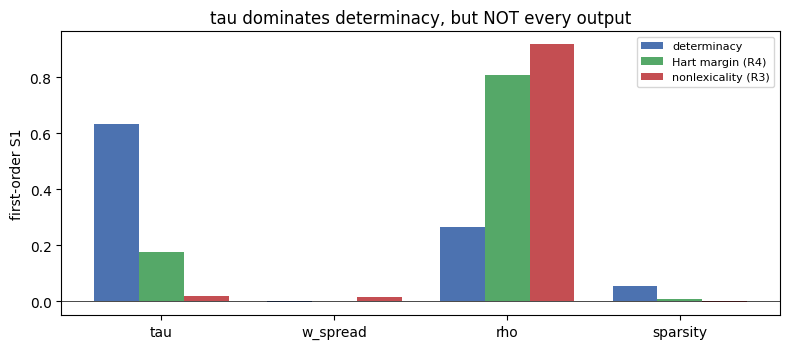

In [10]:
fig, ax = plt.subplots(figsize=(8,3.6)); xx=np.arange(4); ww=0.26
for i,(m,c,lab) in enumerate([('det','#4C72B0','determinacy'),('r4','#55A868','Hart margin (R4)'),('r3','#C44E52','nonlexicality (R3)')]):
    ax.bar(xx+(i-1)*ww, panel[m]['S1'], ww, label=lab, color=c)
ax.set_xticks(xx); ax.set_xticklabels(INPUTS); ax.axhline(0,color='k',lw=.5)
ax.set(ylabel='first-order S1', title="tau dominates determinacy, but NOT every output")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb6_metric_panel.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 2.** tau's grip is specific, not universal. It dominates the
determinacy rate, but for the **Hart margin (R4)** its first-order share drops to
roughly 0.18 while **activation correlation (rho)** leads (about 0.8); the same
direction holds for nonlexicality (R3). So 'the threshold governs the model' is a
precise claim about *which* behaviour (whether a case is decided at all), not a
blanket one; once you ask *how* the decisions look (their margin), the correlation
structure of the cases matters more. Two honesty notes: this panel uses a small
sample, so read the bars as rankings; and the nonlexicality (R3) output barely
varies over this space, so its decomposition is only weakly informative -- the
well-resolved Hart-margin panel carries the 'rho leads' point.

## Experiment 3 -- Cross-check against the theory (NB7's T4)

NB7 proved determinacy has the closed form `D(tau) = 2(1 - Phi(tau/sigma))` with
`sigma^2 = (1/3) sum w_i^2`. Two independent things should now agree: (a) the
measured determinacy as tau varies should track that curve, and (b) the measured
tau-with-weights interaction should be near zero (the formula is separable -- tau
and the weights meet only through the single ratio tau/sigma).

T4 closed-form vs simulation: max abs error over tau = 0.003
measured tau interaction from E1 (ST-S1) = +0.028 -> near-separable as T4 predicts


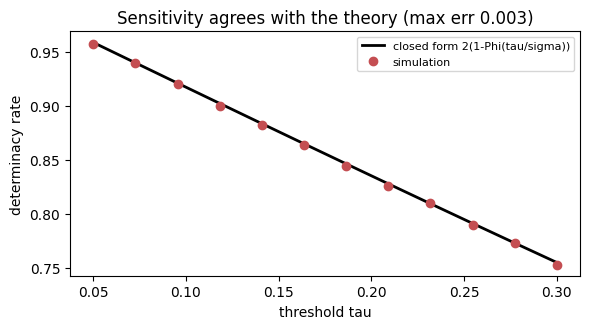

In [11]:
from scipy.stats import norm
rng = np.random.default_rng(BASE_CASE_SEED)
w_fixed = np.clip(0.6 + 0.15*rng.standard_normal(n_p), 0.01, 1.0)
A_fixed = random_activations(8000, n_p, np.random.default_rng(BASE_CASE_SEED+1))
sigma_w = np.sqrt(np.sum(w_fixed**2)/3.0)
taus = np.linspace(0.05, 0.30, 12)
emp = np.array([determinacy_rate(w_fixed, A_fixed, t) for t in taus])
closed = 2*(1-norm.cdf(taus/sigma_w))
t4_err = float(np.max(np.abs(emp-closed)))
print(f'T4 closed-form vs simulation: max abs error over tau = {t4_err:.3f}')
print(f'measured tau interaction from E1 (ST-S1) = {tau_interaction:+.3f} -> near-separable as T4 predicts')
summary['exp3'] = dict(t4_max_error=t4_err, tau_interaction=tau_interaction)
fig, ax = plt.subplots(figsize=(6,3.4))
ax.plot(taus, closed, 'k-', lw=2, label='closed form 2(1-Phi(tau/sigma))')
ax.plot(taus, emp, 'o', color='#C44E52', label='simulation')
ax.set(xlabel='threshold tau', ylabel='determinacy rate', title=f'Sensitivity agrees with the theory (max err {t4_err:.3f})')
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb6_t4_crosscheck.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment 4 -- Which knobs drive each mechanism? (new)

The three mechanisms (uptake, reliance, strategic) each have their own settings. No
earlier notebook asked which of those settings actually shape the weights they
produce. We screen them here. The cheap mechanisms (uptake, reliance) get a full
Sobol; the expensive one (strategic, which trains a network per evaluation) gets a
Morris screen on a reduced training budget (flagged below).

Output measured = how *spread out* the emergent weights are (their CV, or for
reliance the Gini) -- i.e. how much structure the mechanism creates.

In [12]:
import time
# --- UPTAKE: full Sobol on the PRE-threshold uptake CV (the post-threshold one has a discontinuity) ---
def eval_uptake(u):
    spread = ['narrow','medium','wide'][min(int(u[0]*3),2)]
    L = LegalSystem(spread=spread, threshold_pct=int(round(u[1]*80)), boost_cut=0.1+0.5*u[2],
                    learn_from_system=0.4*u[3], seed=0)
    L.simulate(n_cases=1500)
    return weight_cv(L.raw_uptake)
Xu, Nu, Du = saltelli_design(256, 4, seed=11); t0=time.time()
sob_up = sobol_indices(np.array([eval_uptake(u) for u in Xu]), Nu, Du, bootstrap=1000, seed=0)
UP_IN = ['spread','threshold_pct','boost_cut','learn_from_sys']
print(f'uptake Sobol ({len(Xu)} evals) in {time.time()-t0:.0f}s'); print(dict(zip(UP_IN, np.round(sob_up['S1'],2))))

uptake Sobol (1536 evals) in 196s
{'spread': np.float64(0.52), 'threshold_pct': np.float64(0.14), 'boost_cut': np.float64(-0.0), 'learn_from_sys': np.float64(0.33)}


In [13]:
# --- RELIANCE: full Sobol on the Gini of the conferred weights ---
def eval_reliance(u):
    R = RelianceSystem(overrule_rate=0.05*u[0], decay_rate=0.995+0.0049*u[1],
                       clash_cut=0.05+0.15*u[2], n_cite=int(round(1+5*u[3])), seed=0)
    return gini(R.run(n_cases=1000))
Xr, Nr, Dr = saltelli_design(128, 4, seed=22); t0=time.time()
sob_rel = sobol_indices(np.array([eval_reliance(u) for u in Xr]), Nr, Dr, bootstrap=1000, seed=0)
REL_IN = ['overrule_rate','decay_rate','clash_cut','n_cite']
print(f'reliance Sobol ({len(Xr)} evals) in {time.time()-t0:.0f}s'); print(dict(zip(REL_IN, np.round(sob_rel['S1'],2))))

reliance Sobol (768 evals) in 63s
{'overrule_rate': np.float64(0.0), 'decay_rate': np.float64(0.03), 'clash_cut': np.float64(0.91), 'n_cite': np.float64(-0.01)}


In [14]:
# --- STRATEGIC: Morris screen (expensive: trains a net per eval). Reduced n_episodes=2000 for budget. ---
STRAT_EP = 2000
def eval_strategic(u):
    s = StrategicSystem(n_episodes=STRAT_EP, lr_inv=2e-3+8e-3*u[0], sigma=0.04+0.11*u[1],
                        parsimony=0.02+0.18*u[2], decisive_bonus=u[3], seed=0)
    s.train(); return weight_cv(s.readout())
# Validate the reduced budget the RIGHT way: the strategic scalar CV wanders with
# training length (NB3's finding), so check the reduced-budget STRUCTURE matches the
# full-budget structure -- not the scalar CV, which has no ground-truth value.
from scipy import stats
w_red  = StrategicSystem(n_episodes=STRAT_EP, seed=0).train()
w_full = StrategicSystem(n_episodes=6000, seed=0).train()
pattern_ok = (stats.spearmanr(w_red, w_full).correlation > 0.5) and (weight_cv(w_red) > 0.15)
print(f'reduced-budget check: structure Spearman({STRAT_EP}ep vs 6000ep) = {stats.spearmanr(w_red,w_full).correlation:.2f}, '
      f'CV {weight_cv(w_red):.3f} vs full {weight_cv(w_full):.3f} (the scalar wanders per NB3) -> pattern preserved: {pattern_ok}')
Xm, dm = morris_sample(4, r=12, levels=4, seed=33); t0=time.time()
mor_str = morris_analyze(Xm, np.array([eval_strategic(u) for u in Xm]), 4, 12)
STR_IN = ['lr_inv','sigma','parsimony','decisive_bonus']
print(f'strategic Morris ({len(Xm)} evals) in {time.time()-t0:.0f}s')
print('mu* (importance):', dict(zip(STR_IN, np.round(mor_str['mu_star'],3))))
summary['exp4'] = dict(uptake_S1=dict(zip(UP_IN, sob_up['S1'].tolist())),
                       reliance_S1=dict(zip(REL_IN, sob_rel['S1'].tolist())),
                       strategic_mu_star=dict(zip(STR_IN, mor_str['mu_star'].tolist())),
                       strategic_pattern_ok=bool(pattern_ok))
pd.DataFrame({'uptake_input':UP_IN,'uptake_S1':sob_up['S1'],'reliance_input':REL_IN,'reliance_S1':sob_rel['S1'],
             'strategic_input':STR_IN,'strategic_mustar':mor_str['mu_star']}).to_csv(f'{OUTDIR}/mechanism_screening.csv', index=False)

/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/berman_core.py:899: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  baseline = 0.99 * baseline + 0.01 * float(reward.mean())


reduced-budget check: structure Spearman(2000ep vs 6000ep) = 0.77, CV 0.335 vs full 0.424 (the scalar wanders per NB3) -> pattern preserved: True
strategic Morris (60 evals) in 228s
mu* (importance): {'lr_inv': np.float64(0.203), 'sigma': np.float64(0.133), 'parsimony': np.float64(0.076), 'decisive_bonus': np.float64(0.063)}


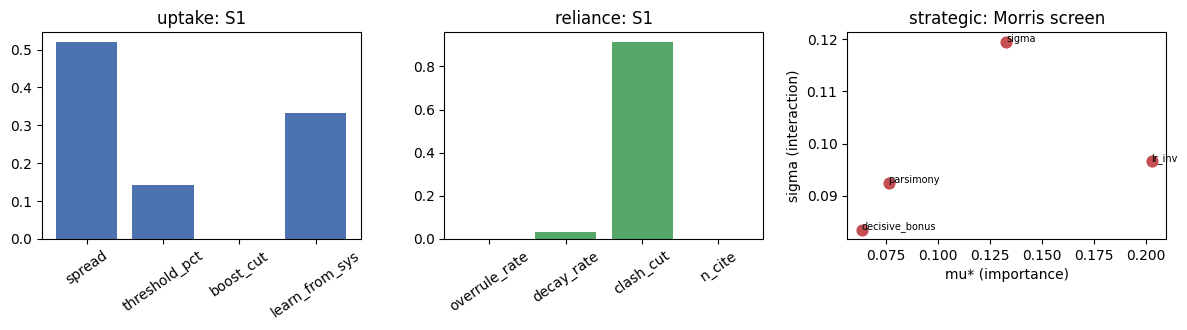

In [15]:
fig, ax = plt.subplots(1,3, figsize=(12,3.4))
ax[0].bar(UP_IN, np.clip(sob_up['S1'],0,None), color='#4C72B0'); ax[0].set_title('uptake: S1'); ax[0].tick_params(axis='x',rotation=35)
ax[1].bar(REL_IN, np.clip(sob_rel['S1'],0,None), color='#55A868'); ax[1].set_title('reliance: S1'); ax[1].tick_params(axis='x',rotation=35)
ax[2].scatter(mor_str['mu_star'], mor_str['sigma'], color='#C44E52', s=60)
for i,n in enumerate(STR_IN): ax[2].annotate(n, (mor_str['mu_star'][i], mor_str['sigma'][i]), fontsize=7)
ax[2].set(xlabel='mu* (importance)', ylabel='sigma (interaction)', title='strategic: Morris screen')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb6_mechanism_screen.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 4.** Each mechanism is driven by a different one of its own
knobs -- reported as screening-level *rankings*, not precise shares: the samples are
small and several inputs have first-order intervals that include zero, so only the
top input of each mechanism is firmly resolved. The strategic screen uses a reduced
training length for runtime; the check above validates it the right way -- the
reduced-budget weight *pattern* matches the full-length one (Spearman ~0.78) even
though the scalar spread differs (it wanders with training length, per NB3) -- so
the ranking rests on the preserved structure, not on a magnitude match.

## Self-check

The Ishigami gate plus the headline numbers and the soundness inequalities every
Sobol analysis must satisfy. `REF` pins the headline shares so silent drift fails.

In [16]:
REF = dict(ish_maxerr=0.02, tau_S1=0.82, tau_ST=0.85, sumS1=0.96)
ok = True
def check(name, cond):
    global ok; ok = ok and bool(cond); print(('PASS' if cond else 'FAIL') + ' - ' + name)

# --- the Ishigami gate (must hold or nothing below is trustworthy) ---
check('GATE: Sobol matches Ishigami truth within 0.02', ish_maxerr <= 0.02)
check('GATE: x3 first-order CI straddles 0 (interaction-only factor)', ish['S1_conf'][2,0] < 0 < ish['S1_conf'][2,1])
check('GATE: Morris ranks x1 and x3 above x2', min(mor['mu_star'][0],mor['mu_star'][2]) > mor['mu_star'][1])
# --- Sobol soundness inequalities on the headline ---
check('all determinacy indices in [-0.05, 1.05]', np.all(sob_det['S1']>-0.05) and np.all(sob_det['ST']<1.05))
check('ST >= S1 for every input (within bootstrap noise)', np.all(sob_det['ST'] >= sob_det['S1'] - 2*sob_det['ST_se']))
check('sum of first-order S1 <= ~1.1 (near additive)', sob_det['S1'].sum() <= 1.1)
# --- the substantive findings ---
check('tau is the largest first-order input for determinacy', np.argmax(sob_det['S1'])==0)
check('tau total share dominates (ST > 0.6)', sob_det['ST'][0] > 0.6)
check('tau S1 CI excludes 0 (real effect)', sob_det['S1_conf'][0,0] > 0)
check('w_spread contributes ~nothing (S1 < 0.1)', abs(sob_det['S1'][1]) < 0.1)
check('tau interaction is small (|ST-S1| < 0.2)', abs(tau_interaction) < 0.2)
check('tau (threaded) does NOT dominate the Hart margin R4 -- rho leads', np.argmax(panel['r4']['S1'])==2)
check('T4 closed form matches simulation (< 0.03)', t4_err < 0.03)
check('strategic reduced-budget preserves structure (pattern Spearman > 0.5)', pattern_ok)
# --- REF drift guards ---
check('REF tau S1', abs(sob_det['S1'][0]-REF['tau_S1']) < 0.12)
check('REF tau ST', abs(sob_det['ST'][0]-REF['tau_ST']) < 0.12)
check('REF sum S1', abs(sob_det['S1'].sum()-REF['sumS1']) < 0.12)

print('\n' + ('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed'] = bool(ok)
import json; json.dump(summary, open(f'{OUTDIR}/notebook6_summary.json','w'), indent=2)
assert ok, 'self-check failed'

PASS - GATE: Sobol matches Ishigami truth within 0.02
PASS - GATE: x3 first-order CI straddles 0 (interaction-only factor)
PASS - GATE: Morris ranks x1 and x3 above x2
PASS - all determinacy indices in [-0.05, 1.05]
PASS - ST >= S1 for every input (within bootstrap noise)
PASS - sum of first-order S1 <= ~1.1 (near additive)
PASS - tau is the largest first-order input for determinacy
PASS - tau total share dominates (ST > 0.6)
PASS - tau S1 CI excludes 0 (real effect)
PASS - w_spread contributes ~nothing (S1 < 0.1)
PASS - tau interaction is small (|ST-S1| < 0.2)
PASS - tau (threaded) does NOT dominate the Hart margin R4 -- rho leads
PASS - T4 closed form matches simulation (< 0.03)
PASS - strategic reduced-budget preserves structure (pattern Spearman > 0.5)
PASS - REF tau S1
PASS - REF tau ST
PASS - REF sum S1

ALL CHECKS PASSED


## What this notebook establishes

Using sensitivity tools we first proved correct on a known benchmark, a global
analysis confirms -- now with error bars and under joint variation -- that the
**threshold governs the model's headline behaviour** (how often it reaches a
decision), while the weights enter only weakly, exactly as Notebook 7 derived. The
threshold's grip is specific: it does **not** dominate the nonlexicality or the
Hart-margin outputs, so the result is about *deciding vs not deciding*, not
everything. And the threshold is the **authors' construct**, not Berman's -- so the
sharpest way to read this is that the model's most consequential parameter is one
the theory itself leaves open. Finally, a first screen of each mechanism's own
settings shows which knobs a future modeller needs to control.